In [2]:
import importlib
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

project_root = Path.cwd().resolve()
while not (project_root / "Experiments" / "parameter_tuning.py").is_file():
    if project_root.parent == project_root:
        raise FileNotFoundError("Could not locate the project root.")
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

import Experiments.plot_parameter_tuning as parameter_tuning
from Experiments.parameter_tuning import (
    DEFAULT_LP_BOUNDS,
    ContaminationScenario,
    tune_scenario,
    write_results_csv,
)

plt.style.use("seaborn-v0_8-whitegrid")

In [3]:
n = 1000
beta = np.array([1.0, 1.0])
x_min, x_max = -2, 2
epsilon = 1e-2
maxiter = 200
tolerance = 1e-6
lp_bounds = DEFAULT_LP_BOUNDS

proportions = [0.02, 0.1, 0.25]
magnitudes = [0.1, 0.5, 5]
experiments = 50
rounds = 10

In [4]:
seed = 42
scenarios = tuple(
    ContaminationScenario(f"scenario_{index + 1}", proportion, magnitude)
    for index, (proportion, magnitude) in enumerate(
        zip(proportions, magnitudes, strict=True)
    )
)

experiment_start = time.perf_counter()
tuning_results = tuple(
    tune_scenario(
        scenario,
        experiments=experiments,
        rounds=rounds,
        seed=seed,
        n=n,
        beta=tuple(beta),
        noise_std=epsilon,
        x_min=x_min,
        x_max=x_max,
        lp_bounds=lp_bounds,
        maxiter=maxiter,
        tolerance=tolerance,
    )
    for scenario in scenarios
)

for result in tuning_results:
    print(
        f"{result.scenario.name} (p={result.scenario.proportion:g}, "
        f"A={result.scenario.magnitude:g}): "
        f"lp={result.best.lp:.6g}, eps={result.best.eps:.6g}, "
        f"mean coefficient recovery error={result.best.mean_error:.6g}"
    )

output_path = project_root / "results" / "parameter_tuning.csv"
write_results_csv(tuning_results, output_path)
elapsed_seconds = time.perf_counter() - experiment_start
simulation_count = sum(
    len(evaluation.experiment_errors)
    for result in tuning_results
    for evaluation in result.evaluations
)
print(f"Per-experiment results saved to {output_path}")
print(f"Simulations run: {simulation_count}")
print(f"Total experiment time: {elapsed_seconds:.3f} seconds")

scenario_1 (p=0.02, A=0.1): lp=0.712744, eps=0.0121471, mean coefficient recovery error=0.000378655
scenario_2 (p=0.1, A=0.5): lp=0.650488, eps=0.0114187, mean coefficient recovery error=0.000406257
scenario_3 (p=0.25, A=5): lp=0.462744, eps=0.0201465, mean coefficient recovery error=0.000417333
Per-experiment results saved to /Users/pabloortizbadenes/Desktop/Misc/Proyectos/nonconvex_regression/results/parameter_tuning.csv
Simulations run: 6000
Total experiment time: 5.542 seconds


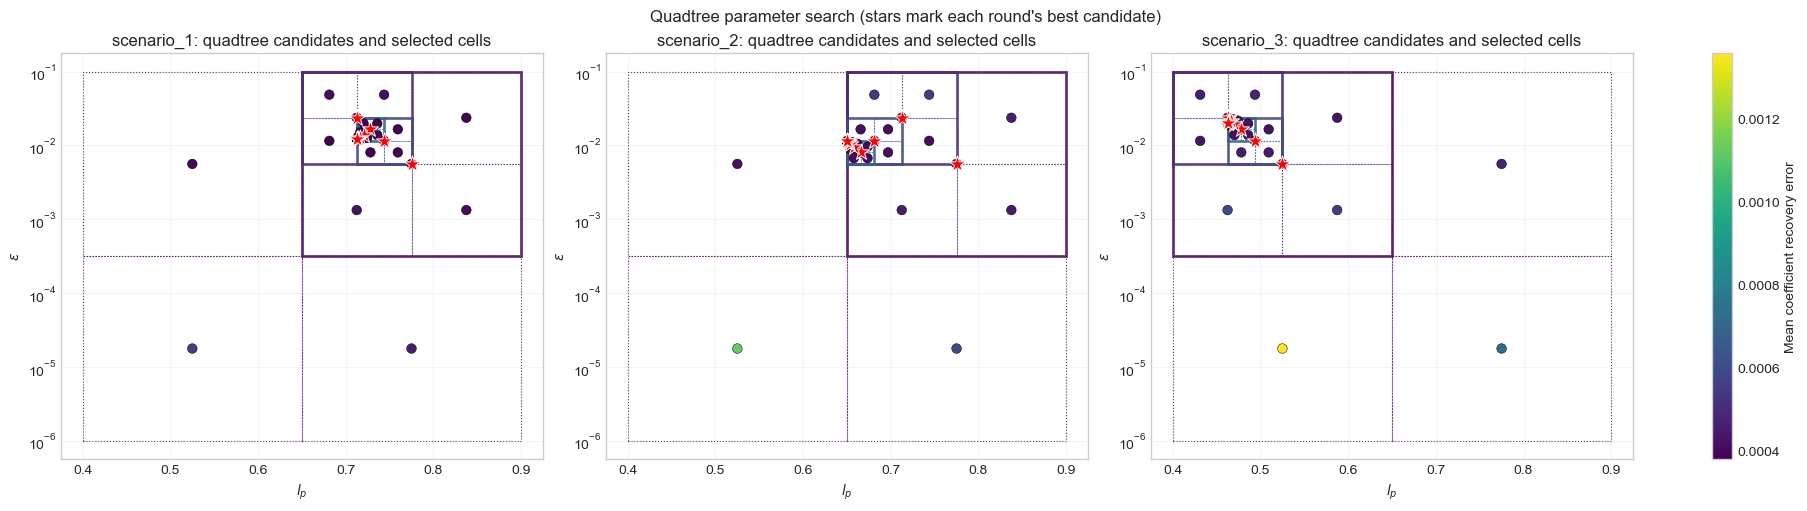

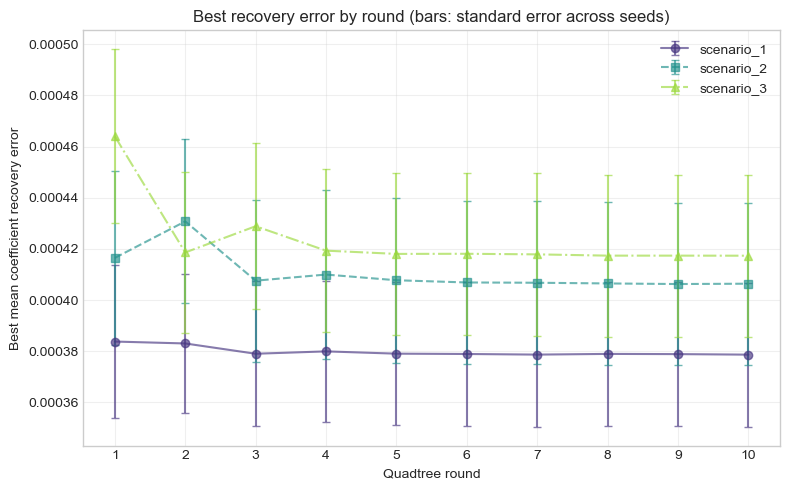

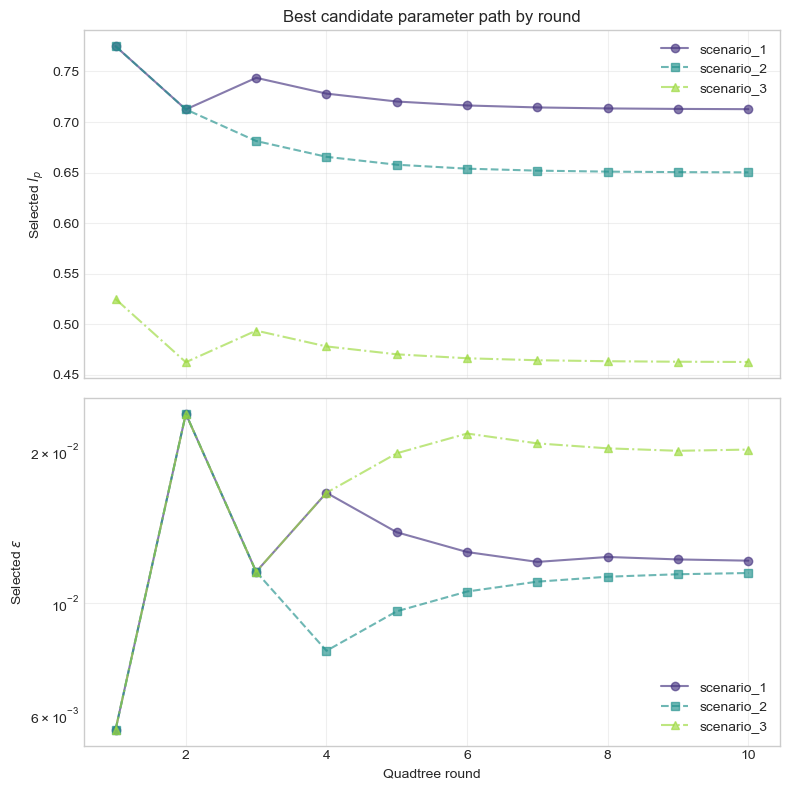

In [5]:
importlib.reload(parameter_tuning)
figures = parameter_tuning.plot_parameter_tuning(output_path, lp_bounds=lp_bounds)
for figure in figures:
    display(figure)
    plt.close(figure)